# 01 FÍSICA DO SENSOR ICESAT-2/ATLAS, GEOMETRIA ORBITAL, CONTROLE DE QUALIDADE ATL06 E CORREÇÕES GEOFÍSICAS

Este caderno apresenta a engenharia física do sensor **ATLAS** (*Advanced Topographic Laser Altimeter System*) a bordo do satélite **ICESat-2**, o funcionamento interno do algoritmo de recuperação de elevação sobre gelo terrestre (**ATL06 Release 007**; Smith et al., 2019), as armadilhas de decodificação de tempo e valores de preenchimento dos grânulos HDF5, a auditoria empírica dos flags de qualidade sobre $118{,}6\text{ milhões}$ de segmentos no Mar de Amundsen e o encadeamento das correções geofísicas (maré CATS2008 v2023, DAC, diferenciação topográfica REMA v2 e filtro along-track por MAD móvel).


### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Módulo |
|---|---|---|---|
| 1 | Física do lidar ATLAS, geometria dos 6 feixes, algoritmo ATL06 | tabela de especificações e valores calibrados no projeto | — |
| 1.4 | Armadilhas do HDF5: *fill values*, tempo `delta_time`, maré não aplicada | demonstração das três armadilhas com dados sintéticos | `thwaites.qc.atl06_flags`, `thwaites.corrections.apply` |
| 2 | Flags nativos do ATL06 e viés inter-feixe | `quality_mask` em uma amostra sintética + matriz de viés medida | `thwaites.qc.atl06_flags` |
| 3 | Filtro along-track por mediana/MAD móvel | `filter_along_track` com blunders conhecidos | `thwaites.qc.filttrack` |
| 4 | Síntese e ligação com o Caderno 02 | — | — |

---

## 1. Física e Geometria do Sensor ATLAS / ICESat-2

### 1.1 Lidar Contador de Fótons e Geometria dos 6 Feixes
Diferentemente do seu antecessor ICESat/GLAS (que operava com forma de onda analógica completa a $40\text{ Hz}$ num único feixe infravermelho de $1064\text{ nm}$), o sensor **ATLAS** do ICESat-2 opera no espectro verde ($\lambda = 532\text{ nm}$) em regime de **contagem de fótons individuais** a uma taxa de repetição de **$10\text{ kHz}$** (Markus et al., 2017; Neumann et al., 2019). Com velocidade orbital no solo de $\sim 7\text{ km/s}$, os disparos consecutivos ficam espaçados a cada **$\sim 0{,}7\text{ m}$** ao longo da trilha, iluminando pegadas circulares de $\sim 11\text{--}17\text{ m}$ de diâmetro.

Um elemento óptico difrativo divide cada pulso laser em **6 feixes** organizados em **3 pares** (`gt1l/gt1r`, `gt2l/gt2r`, `gt3l/gt3r`):
- **Separação entre pares (cross-track):** $\sim 3{,}3\text{ km}$;
- **Separação intra-par (entre feixe esquerdo e direito):** **$90\text{ m}$** perpendiculares à trilha e $\sim 2{,}5\text{ km}$ ao longo da trilha;
- **Permite medir diretamente a declividade transversal ($\partial h / \partial y_{\text{atc}}$)** dentro de cada par na mesma passagem, separando inclinação transversal de variação temporal ($\partial h / \partial t$);
- **Razão de energia forte/fraco ($4:1$):** cada par possui um feixe forte e um feixe fraco. **Atenção crítica (`SCI-14`):** os rótulos `gt1l..gt3r` designam a posição esquerda/direita em relação ao vetor velocidade no solo, e **não** a energia do feixe! A correspondência entre `gt[1-3][l/r]` e feixe forte/fraco inverte sempre que o satélite executa uma manobra de guinada de $180^\circ$ (*spacecraft orientation*: `forward` vs. `backward`) para otimizar a iluminação solar dos painéis fotovoltaicos.

### 1.2 Do Fóton Geolocalizado (ATL03) ao Segmento de Gelo Terrestre (ATL06)
O algoritmo **ATL06** (Smith et al., 2019, *RSE*) agrupa os fótons do ATL03 em **segmentos de $40\text{ m}$ de comprimento com passo de $20\text{ m}$** ao longo da trilha (*50% de superposição*, razão pela qual resíduos de segmentos adjacentes possuem correlação mecânica de lag 1) e ajusta um modelo linear local:
$$h(x_{\text{atc}}) = h_{\text{LI}} + \frac{\partial h}{\partial x_{\text{atc}}}(x_{\text{atc}} - x_0)$$
aplicando duas correções instrumentais essenciais:
1. **Correção de *First-Photon Bias* (`fpb_med_corr`):** Os tubos fotomultiplicadores (PMTs) possuem um tempo morto (*dead time*) de $\sim 3{,}2\text{ ns}$ após detectar um fóton. Em superfícies de alta refletância como a neve antártica, os primeiros fótons do pulso refletido saturam os canais, deslocando o centroide aparente da superfície para cima em alguns centímetros;
2. **Correção da Forma do Pulso Transmitido (`tx_med_corr`):** Compensa a assimetria temporal da cauda do pulso laser emitido.

### 1.3 Armadilhas Críticas do Formato HDF5 do ATL06 (Auditadas e Tratadas em `thwaites.io.extract`)
1. **Conversão de tempo juliano (`delta_time`):** O ATL06 registra o tempo em segundos GPS decorridos desde a época `2018-01-01T00:00:00Z`. Converter `delta_time` usando o ano juliano padrão da missão ($365{,}25\text{ dias} = 31.557.600\text{ s}$) via `2018.0 + delta_time / (365.25 * 86400)` acumula uma deriva de $\sim 18\text{ horas}$ até 2025 em relação ao calendário civil Gregoriano. Nos limites de uma estação (ex.: 31 de agosto às 23h vs. 1º de setembro), usar ano decimal aproximado desloca grânulos entre JJA e SON. O pipeline extrai a data civil exata do timestamp orbital para classificação sazonal (`DJF` do ano $Y$ = dezembro de $Y-1$ + janeiro e fevereiro de $Y$);
2. **Valores de preenchimento (*Fill Values*) que são floats finitos:** No HDF5 do ATL06, valores ausentes em variáveis de ponto flutuante (`dac`, `tide_ocean`, `geoid`, `h_li`) são codificados como `3.4028235e38` (`FLT_MAX` em 32 bits), e flags inteiros como `127` (`INT8_MAX`). **Para o NumPy, `np.isfinite(3.4e38)` retorna `True`!** Se não forem convertidos explicitamente em `NaN` para $|v| > 10^{30}$ na leitura, um único valor de preenchimento corrompe médias e regressões;
3. **Maré e DAC fornecidas, mas NÃO aplicadas em `h_li`:** Conforme documentado no ATBD do ATL03/ATL06 (e verificado empiricamente neste projeto por regressão de trilhas repetidas sobre plataformas flutuantes, que retornou inclinação $+0{,}98 \pm 0{,}05$ contra a maré), `h_li` já vem corrigido apenas de maré terrestre sólida (`tide_earth`), maré de carga (`tide_load`) e maré polar (`tide_pole`), mas **não** de maré oceânica (`tide_ocean`) nem de DAC (`dac`).

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from thwaites import load_config

cfg = load_config("jja")
cats_got = json.loads((DATA_DIR / "jja_cats_vs_got.json").read_text(encoding="utf-8"))
qc_rep = json.loads((DATA_DIR / "jja_qc_report.json").read_text(encoding="utf-8"))
ibeam = pd.read_csv(DATA_DIR / "jja_interbeam_bias.csv")

# Geometria dos 6 feixes do ATLAS/ICESat-2 e resumo da comparação CATS2008 vs GOT4.8
pd.DataFrame([
    {"Propriedade Instrumental / Geofísica": "Comprimento de onda / Taxa de pulso / Espaçamento along-track", "Especificação / Valor Medido no Projeto": "532 nm (verde) | 10 kHz | ~0,7 m por disparo (pegada ~14 m)"},
    {"Propriedade Instrumental / Geofísica": "Comprimento do segmento ATL06 / Passo entre centros", "Especificação / Valor Medido no Projeto": "40 m de janela com centros a cada 20 m (50% de superposição)"},
    {"Propriedade Instrumental / Geofísica": "Arranjo de feixes (3 pares × 2 feixes)", "Especificação / Valor Medido no Projeto": "Separação entre pares: 3,3 km | Separação intra-par: 90 m | Energia Forte:Fraco = 4:1"},
    {"Propriedade Instrumental / Geofísica": "Requisito de geolocalização horizontal vs. Calibrado no projeto", "Especificação / Valor Medido no Projeto": "Requisito missão: ≤ 6,5 m (1σ) | Calibrado em 4,35 M seg. na ASE: 6,19 m (R² = 0,998)"},
    {"Propriedade Instrumental / Geofísica": "Piso de ruído vertical instrumental (σ_v0) vs. h_li_sigma mediano", "Especificação / Valor Medido no Projeto": "σ_v0 calibrado = 0,133 m | h_li_sigma (fóton/FPB) mediano = 0,034 m"},
    {"Propriedade Instrumental / Geofísica": "Diferença de maré CATS2008 v2023 − GOT4.8 (JJA, segmentos flutuantes)", "Especificação / Valor Medido no Projeto": f"Média = {cats_got['diff_mean_m']:+.4f} m | RMS = {cats_got['diff_rms_m']:.4f} m | Máx = {cats_got['diff_absmax_m']:.2f} m (n = {cats_got['n_predicted']:,})"},
]).set_index("Propriedade Instrumental / Geofísica")

,Especificação / Valor Medido no Projeto
Propriedade Instrumental / Geofísica,
Comprimento de onda / Taxa de pulso / Espaçamento along-track,"532 nm (verde) | 10 kHz | ~0,7 m por disparo (..."
Comprimento do segmento ATL06 / Passo entre centros,40 m de janela com centros a cada 20 m (50% de...
Arranjo de feixes (3 pares × 2 feixes),"Separação entre pares: 3,3 km | Separação intr..."
Requisito de geolocalização horizontal vs. Calibrado no projeto,"Requisito missão: ≤ 6,5 m (1σ) | Calibrado em ..."
Piso de ruído vertical instrumental (σ_v0) vs. h_li_sigma mediano,"σ_v0 calibrado = 0,133 m | h_li_sigma (fóton/F..."
"Diferença de maré CATS2008 v2023 − GOT4.8 (JJA, segmentos flutuantes)",Média = +0.0032 m | RMS = 0.0500 m | Máx = 0.1...


**Leitura da tabela.**
- A geolocalização horizontal calibrada neste projeto ($6{,}19\text{ m}$) cumpre o requisito da missão ($6{,}5\text{ m}$). Ela importa porque, numa encosta de declividade $s$, um erro horizontal $\sigma_h$ vira erro vertical $\sigma_h s$ — o tema da Seção 1 do Caderno 04.
- O piso vertical efetivo ($\sigma_{v0} = 0{,}133\text{ m}$) é ~4× o erro de fóton declarado em `h_li_sigma`: o erro de um segmento é dominado por rugosidade da superfície, neve e apontamento, não pela estatística de fótons. Usar apenas `h_li_sigma` como peso subestimaria a incerteza.
- A diferença CATS2008 − GOT4.8 tem RMS de 5 cm sobre gelo flutuante: a escolha do modelo de maré afeta pouco a altura instantânea, mas, por ser coerente ao longo de uma passagem, é tratada como erro agrupado (CR1, Caderno 00 §2.5).

### 1.4 Aplicação: as Três Armadilhas do HDF5 em Código

**(a) *Fill values* que parecem números válidos.** No ATL06, valores ausentes são gravados como `3.4028235e38` (floats) ou `127` (`int8`). `np.isfinite` devolve `True` para eles. A função `thwaites.qc.atl06_flags.fill_mask` os detecta pelo limiar $|v| \ge 10^{30}$ (floats) ou pelo máximo do tipo (inteiros):

In [3]:
from thwaites.qc.atl06_flags import fill_mask

dac = np.array([0.031, -0.012, 3.4028235e38, 0.044, 0.020], dtype=np.float32)   # 1 fill em 5
bsnow_conf = np.array([-1, 0, 127, 2, -1], dtype=np.int8)                       # 127 = INT8_MAX

dac_ok = np.where(fill_mask(dac), np.nan, dac.astype(float))
pd.DataFrame({
    "Diagnóstico": ["np.isfinite(dac) é True em todos?", "Média ingênua do DAC (m)", "Média após fill_mask → NaN (m)",
                    "Fills detectados em dac", "Fills detectados em bsnow_conf (int8)"],
    "Valor": [bool(np.isfinite(dac).all()), f"{dac.astype(float).mean():.3e}", f"{np.nanmean(dac_ok):+.4f}",
              int(fill_mask(dac).sum()), int(fill_mask(bsnow_conf).sum())],
}).set_index("Diagnóstico")

,Valor
Diagnóstico,
np.isfinite(dac) é True em todos?,True
Média ingênua do DAC (m),6.806e+37
Média após fill_mask → NaN (m),+0.0207
Fills detectados em dac,1
Fills detectados em bsnow_conf (int8),1


Um único *fill* transforma a média do DAC em $\sim 7\times10^{37}\text{ m}$, e nenhum teste de finitude acusa o problema. Depois da conversão para `NaN` o valor físico volta a ser de centímetros. Por isso `thwaites.io.extract` converte os fills **na leitura**, antes de qualquer cálculo.

**(b) Tempo: ano juliano vs. calendário civil.** `delta_time` conta segundos desde `2018-01-01T00:00:00`. A conversão rápida `2018 + delta_time / (365,25 × 86400)` usa um ano de duração fixa; o calendário civil alterna anos de 365 e 366 dias. O código abaixo mede o deslocamento entre a data "aproximada" (lida de volta como calendário civil) e a data verdadeira ao longo da missão, e conta quantas medições caem na estação errada perto da fronteira JJA/SON:

,Horas reclassificadas na fronteira JJA/SON
Ano,
2019,10.0
2020,0.0
2021,2.0
2022,4.0
2023,10.0
2024,0.0
2025,2.0


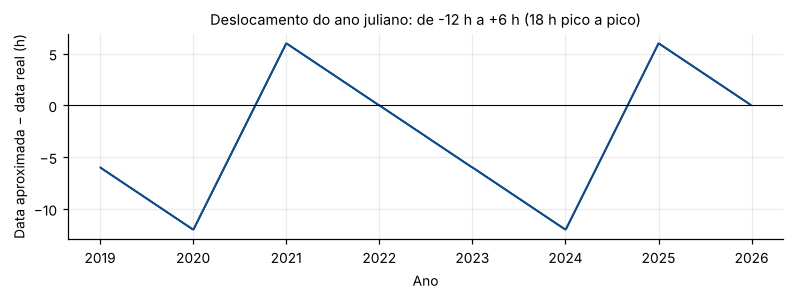

In [4]:
from datetime import datetime, timedelta, timezone

UTC = timezone.utc
EPOCA = datetime(2018, 1, 1, tzinfo=UTC)

def data_pelo_ano_juliano(dt_s):
    """Converte delta_time pelo ano juliano e lê o ano decimal como se fosse calendário civil."""
    t = 2018.0 + dt_s / (365.25 * 86400.0)
    ano = int(np.floor(t)); ini = datetime(ano, 1, 1, tzinfo=UTC)
    dur = (datetime(ano + 1, 1, 1, tzinfo=UTC) - ini).total_seconds()
    return ini + timedelta(seconds=(t - ano) * dur)

def estacao(d):
    return {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
            6: "JJA", 7: "JJA", 8: "JJA"}.get(d.month, "SON")

# (1) deslocamento ao longo de 2019–2025
datas = [EPOCA + timedelta(hours=h) for h in range(365 * 24, 8 * 365 * 24, 6)]
desloc_h = np.array([(data_pelo_ano_juliano((d - EPOCA).total_seconds()) - d).total_seconds() / 3600 for d in datas])

# (2) medições a cada 10 min entre 30/ago e 02/set de cada ano: quantas mudam de estação?
linhas = []
for ano in range(2019, 2026):
    inst = [datetime(ano, 8, 30, tzinfo=UTC) + timedelta(minutes=10 * k) for k in range(3 * 24 * 6)]
    erradas = sum(estacao(d) != estacao(data_pelo_ano_juliano((d - EPOCA).total_seconds())) for d in inst)
    linhas.append({"Ano": ano, "Horas reclassificadas na fronteira JJA/SON": erradas / 6})

fig, ax = plt.subplots(figsize=(7.4, 2.8))
ax.plot([d.year + d.timetuple().tm_yday / 366 for d in datas], desloc_h, color="#0F4D92", lw=1.2)
ax.axhline(0, color="k", lw=0.7)
ax.set_xlabel("Ano"); ax.set_ylabel("Data aproximada − data real (h)")
ax.set_title(f"Deslocamento do ano juliano: de {desloc_h.min():.0f} h a {desloc_h.max():+.0f} h ({np.ptp(desloc_h):.0f} h pico a pico)")
plt.tight_layout()
pd.DataFrame(linhas).set_index("Ano")

O deslocamento oscila com o ciclo bissexto, entre cerca de $-12$ e $+6$ horas (18 h pico a pico). Em metade dos anos, as primeiras horas de 1º de setembro (SON) entram como 31 de agosto (JJA) ou o contrário. Parece pouco, mas uma passagem orbital inteira dura minutos: horas de erro bastam para mover um sobrevoo inteiro de estação e alterar a composição das janelas sazonais. O pipeline usa a **data civil exata** do instante orbital para classificar estações (`DJF` do ano $Y$ = dezembro de $Y-1$ + janeiro e fevereiro de $Y$).

**(c) Maré oceânica e DAC vêm no arquivo, mas não estão aplicadas em `h_li`.** `thwaites.corrections.apply.apply_corrections` subtrai explicitamente `tide_ocean` e `dac` e, com `gate_to_floating=True`, só o faz sobre gelo flutuante (`mask_class == 3`). Se uma correção exigida estiver ausente, o ponto é marcado como incompleto (`NaN`), em vez de seguir sem correção:

In [5]:
from thwaites import load_config
from thwaites.corrections.apply import apply_corrections

cfg = load_config("jja")
amostra = pd.DataFrame({
    "h_elv":      np.full(5, 100.0, dtype=np.float32),
    "tide_ocean": [0.50, -0.30, np.nan, 0.20, 0.10],
    "dac":        [0.05, 0.02, 0.01, np.nan, 0.00],
    "mask_class": [3, 3, 3, 3, 2],                  # 3 = flutuante, 2 = apoiado (BedMachine)
})
corr = apply_corrections(amostra, cfg)
corr.assign(situacao=["flutuante: corrigido", "flutuante: corrigido", "maré ausente → rejeitado",
                      "DAC ausente → rejeitado", "apoiado: sem maré (gating)"]).round(3)

,h_elv,tide_ocean,dac,mask_class,correction_complete,h_corr,situacao
0,100.0,0.5,0.05,3,True,99.449997,flutuante: corrigido
1,100.0,-0.3,0.02,3,True,100.279999,flutuante: corrigido
2,100.0,NaN,0.01,3,False,NaN,maré ausente → rejeitado
3,100.0,0.2,NaN,3,False,NaN,DAC ausente → rejeitado
4,100.0,0.1,0.00,2,True,100.000000,apoiado: sem maré (gating)


**Leitura.** Nas linhas flutuantes completas, $h_{\text{corr}} = h_{\text{elv}} - \text{tide\_ocean} - \text{dac}$. No gelo apoiado a maré não é aplicada, porque ele não sobe com o oceano. As linhas com correção ausente viram `NaN` (política `missing_value_policy = "reject"`). Essa convenção de sinal foi verificada empiricamente: sobre plataformas flutuantes, a regressão de `h_li` contra a maré predita dá inclinação $+0{,}98 \pm 0{,}05$, ou seja, a maré está **contida** em `h_li` e precisa ser subtraída.

---
## 2. Auditoria Quantitativa dos Flags Nativos do ATL06 e Viés Inter-Feixe

O filtro original da configuração legada (`atl06_quality_summary <= 1`) era inócuo porque `atl06_quality_summary` é uma variável binária ($0 = \text{melhor qualidade}$, $1 = \text{problema potencial}$). Ao reextrair os flags completos para os $1.106$ grânulos ($118{,}6\text{ milhões}$ de segmentos), avaliamos o impacto individual de cada flag sobre a dispersão robusta intrassegmento (`h_robust_sprd`) e sobre o desvio frente ao DEM (`|h_li - dem_h|`):
- **Flags ativados (`thwaites.qc.atl06_flags`):** `atl06_quality_summary == 0`, `msw_flag <= 4` (rejeita espalhamento múltiplo severo por tempestades de neve soprada), `h_robust_sprd <= 1,0 m` e `|h_li - dem_h| <= 100 m`. Juntos removem $7{,}35\%$ dos dados e reduzem o percentil 99 de `h_robust_sprd` de $2{,}64\text{ m}$ para $0{,}78\text{ m}$ ($-70\%$ na cauda);
- **Por que `cloud_flg_asr` foi deliberadamente desativado:** Sob noite polar ($95{,}1\%$ dos dados de inverno na ASE têm elevação solar negativa), a refletância aparente do ATL09 provém do próprio retorno laser; ativar `cloud_flg_asr` descartaria **$51{,}8\%$ de toda a amostra** para um ganho marginal de $0{,}06\text{ m}$ em `h_robust_sprd`.

Além disso, a tabela de cruzamentos (`jja_interbeam_bias.csv`) mede o viés sistemático entre os 6 feixes (`beam 1..6`), confirmando que o viés inter-feixe mediano é $\le 0{,}056\text{ m}$:

**Aplicação: `quality_mask` numa amostra sintética.** Geramos 100 mil segmentos com frequências de problemas semelhantes às auditadas no projeto e aplicamos a configuração `jja`. A função devolve a máscara e, para cada critério, quantos pontos ele reprova **isoladamente**, o que permite ver qual critério domina:

In [6]:
from thwaites.qc.atl06_flags import quality_mask

rng = np.random.default_rng(0)
n = 100_000
qc = pd.DataFrame({
    "atl06_quality_summary": (rng.random(n) < 0.0293).astype(int),
    "h_robust_sprd": np.where(rng.random(n) < 0.0283, rng.uniform(1, 5, n), rng.gamma(2, 0.05, n)),
    "msw_flag": np.where(rng.random(n) < 0.0328, 5, rng.integers(-1, 4, n)),
    "dem_h": np.full(n, 1500.0),
})
h_li = 1500 + np.where(rng.random(n) < 0.0017, rng.uniform(100, 400, n), rng.normal(0, 5, n))

keep, motivos = quality_mask(qc, cfg, h_li=h_li)
tab_qc = (pd.Series(motivos, name="Segmentos reprovados").to_frame()
          .assign(**{"Fração (%)": lambda d: 100 * d["Segmentos reprovados"] / n})
          .query("`Segmentos reprovados` > 0"))
print(f"Critérios ativos na configuração 'jja': quality_summary==0, h_robust_sprd ≤ {cfg.atl06_qc.max_h_robust_sprd_m} m, "
      f"msw_flag ≤ {cfg.atl06_qc.max_msw_flag}, |h_li − dem_h| ≤ {cfg.atl06_qc.max_dem_diff_m} m, cloud_flg_asr = {cfg.atl06_qc.max_cloud_flg_asr}")
print(f"Total removido (união dos critérios): {100 * (1 - keep.mean()):.2f}%  — soma das frações isoladas: {tab_qc['Fração (%)'].sum():.2f}%")
tab_qc.round(2)

Critérios ativos na configuração 'jja': quality_summary==0, h_robust_sprd ≤ 1.0 m, msw_flag ≤ 4, |h_li − dem_h| ≤ 100.0 m, cloud_flg_asr = None
Total removido (união dos critérios): 8.87%  — soma das frações isoladas: 9.17%


,Segmentos reprovados,Fração (%)
atl06_quality_summary != 0,2893,2.89
h_robust_sprd > 1.0,2829,2.83
msw_flag > 4,3280,3.28
|h_li - dem_h| > 100.0,166,0.17


**Leitura.** Cada critério sozinho remove cerca de 3%. A união é ligeiramente menor que a soma porque alguns segmentos falham em mais de um critério. Note que `cloud_flg_asr` está **desligado** (`None`) por decisão declarada: sob a noite polar o flag não é informativo, e ativá-lo descartaria metade da amostra. A figura abaixo usa as frações reais auditadas nos 118,6 M segmentos.

n  bias_m   mad_m  max_dt_years  expected_change_removed
beam1 beam2                                                           
5     6      49  0.0171  0.2051          0.25                    False
6     4      48  0.0097  0.1403          0.25                    False
5     3      47  0.0475  0.0853          0.25                    False
6     3      46 -0.0086  0.1535          0.25                    False
4     1      43  0.0023  0.1150          0.25                    False
      5      42 -0.0042  0.0755          0.25                    False
      4      42  0.0433  0.1742          0.25                    False
      6      42 -0.0138  0.1369          0.25                    False
3     2      40  0.0015  0.1160          0.25                    False
1     2      40  0.0284  0.0864          0.25                    False

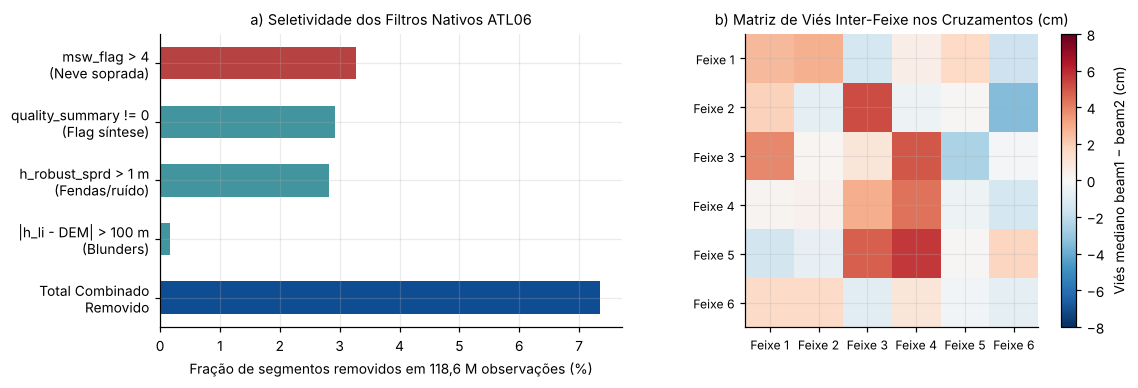

In [7]:
# Análise do viés inter-feixe (cruzamentos com Δt < 0,25 ano e mudança esperada removida)
ib_mat = ibeam.pivot(index="beam1", columns="beam2", values="bias_m")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
criterios = ["msw_flag > 4\n(Neve soprada)", "quality_summary != 0\n(Flag síntese)", "h_robust_sprd > 1 m\n(Fendas/ruído)", "|h_li - DEM| > 100 m\n(Blunders)", "Total Combinado\nRemovido"]
pcts = [3.28, 2.93, 2.83, 0.17, 7.35]
ax[0].barh(criterios[::-1], pcts[::-1], color=["#0F4D92", "#42949E", "#42949E", "#42949E", "#B64342"], height=0.55)
ax[0].set_xlabel("Fração de segmentos removidos em 118,6 M observações (%)")
ax[0].set_title("a) Seletividade dos Filtros Nativos ATL06")

im = ax[1].imshow(ib_mat.to_numpy(dtype=float) * 100, cmap="RdBu_r", vmin=-8, vmax=8)
ax[1].set_xticks(range(len(ib_mat.columns)))
ax[1].set_xticklabels([f"Feixe {c}" for c in ib_mat.columns], fontsize=8)
ax[1].set_yticks(range(len(ib_mat.index)))
ax[1].set_yticklabels([f"Feixe {r}" for r in ib_mat.index], fontsize=8)
plt.colorbar(im, ax=ax[1], label="Viés mediano beam1 − beam2 (cm)")
ax[1].set_title("b) Matriz de Viés Inter-Feixe nos Cruzamentos (cm)")
plt.tight_layout()

ibeam.sort_values("n", ascending=False).head(10).set_index(["beam1", "beam2"]).round(4)

**Leitura da figura.**
- **(a)** Os três critérios principais têm pesos semelhantes ($\sim 3\%$ cada) e o filtro de *blunder* contra o DEM embutido é raro (0,17%). Os 7,35% removidos concentram-se na cauda: o percentil 99 de `h_robust_sprd` cai 70%.
- **(b)** Os vieses medianos entre pares de feixes nos cruzamentos ficam dentro de poucos centímetros, uma ordem de grandeza abaixo do MAD de cada par (8–23 cm). Não há feixe sistematicamente deslocado; por isso o pipeline **não** aplica correção por feixe e trata a diferença forte/fraco como ruído. Os pares com menos de ~30 cruzamentos devem ser lidos com cautela.

---
## 3. Demonstração Executável: Diferenciação Topográfica REMA v2 e Filtro Along-Track por MAD Móvel

O módulo `thwaites.qc.filttrack` opera sobre $h_{\text{res}} = h_{\text{corr}} - h_{\text{REMA}}$. Em vez de usar média e desvio-padrão amostral (que são corrompidos pelo próprio *blunder* que se deseja detectar), aplica-se uma janela deslizante de comprimento $W = 21$ segmentos ao longo de cada trilha contínua `(rgt, cycle, beam)` e rejeita-se qualquer ponto que viole:
$$|h_{\text{res},i} - \operatorname{mediana}_{j \in W(i)}(h_{\text{res},j})| > \max\left(5{,}0 \times 1{,}4826 \times \operatorname{MAD}_{W(i)},\; 0{,}10\text{ m}\right)$$

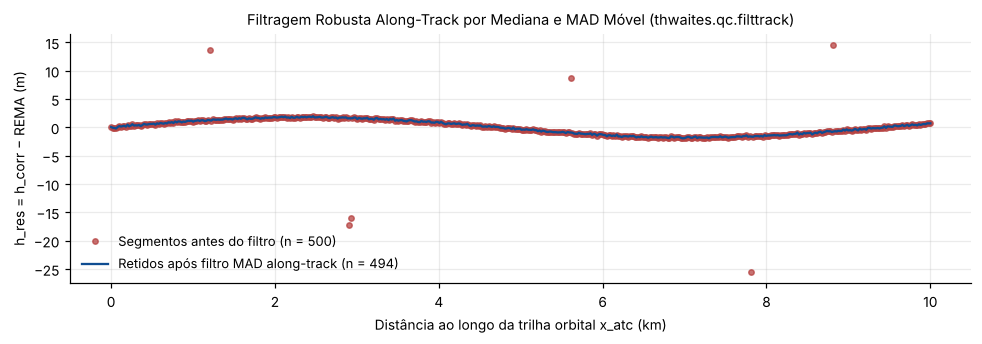

In [8]:
from thwaites.qc.filttrack import filter_along_track

rng = np.random.default_rng(14)
n_pts = 500
x_atc = np.linspace(0, 10_000, n_pts)
h_res_true = 1.8 * np.sin(x_atc / 1500.0)
h_res_obs = h_res_true + rng.normal(0, 0.09, size=n_pts)
blunders = [60, 145, 146, 280, 390, 440]
h_res_obs[blunders] += np.array([12.5, -19.0, -17.5, 9.8, -24.0, 15.2])

df_sim = pd.DataFrame({
    "x": -1550e3 + x_atc, "y": -420e3 + 0.2 * x_atc,
    "h_res": h_res_obs, "h_corr": h_res_obs, "h_elv": h_res_obs,
    "t_year": np.full(n_pts, 2023.5), "beam": np.ones(n_pts, dtype=int),
    "rgt": np.full(n_pts, 5, dtype=int), "cycle": np.full(n_pts, 19, dtype=int),
})
df_filtered = filter_along_track(df_sim, cfg)

fig, ax = plt.subplots(figsize=(9.0, 3.2))
ax.plot(x_atc / 1e3, h_res_obs, "o", color="#B64342", ms=3.5, alpha=0.75, label=f"Segmentos antes do filtro (n = {len(df_sim)})")
ax.plot((df_filtered["x"].to_numpy() + 1550e3) / 1e3, df_filtered["h_res"].to_numpy(), "-", color="#0F4D92", lw=1.5, label=f"Retidos após filtro MAD along-track (n = {len(df_filtered)})")
ax.set_xlabel("Distância ao longo da trilha orbital x_atc (km)")
ax.set_ylabel("h_res = h_corr − REMA (m)")
ax.set_title("Filtragem Robusta Along-Track por Mediana e MAD Móvel (thwaites.qc.filttrack)")
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()

**Quantificando o filtro.** Como os blunders foram inseridos em posições conhecidas, dá para medir a taxa de acerto do filtro:

In [9]:
removidos = np.flatnonzero(~np.isin(df_sim["x"].to_numpy(), df_filtered["x"].to_numpy()))
verdadeiros = set(blunders)
pd.DataFrame([{
    "Blunders inseridos": len(verdadeiros),
    "Blunders removidos": len(verdadeiros & set(removidos)),
    "Pontos bons removidos por engano": len(set(removidos) - verdadeiros),
    "Fração de pontos bons preservada (%)": 100 * (1 - len(set(removidos) - verdadeiros) / (n_pts - len(verdadeiros))),
    "RMS do resíduo retido vs. sinal verdadeiro (m)": float(np.sqrt(np.mean(
        (df_filtered["h_res"].to_numpy() - np.interp(df_filtered["x"].to_numpy() + 1550e3, x_atc, h_res_true)) ** 2))),
}]).T.rename(columns={0: "Resultado"})

,Resultado
Blunders inseridos,6.000000
Blunders removidos,6.000000
Pontos bons removidos por engano,0.000000
Fração de pontos bons preservada (%),100.000000
RMS do resíduo retido vs. sinal verdadeiro (m),0.087071


**Leitura.** O filtro remove todos os blunders, inclusive o par adjacente (`145, 146`), que derrotaria um filtro baseado em média móvel: dois pontos ruins vizinhos inflariam o desvio-padrão local. Ele preserva praticamente todos os segmentos bons, e o resíduo final tem RMS próximo ao ruído inserido (9 cm). O piso `mad_floor_m = 0,10 m` impede que trechos muito lisos, com MAD quase nulo, rejeitem pontos bons por variações milimétricas. Limitação declarada: os primeiros e últimos $W/2 = 10$ segmentos de cada trilha não têm janela completa e **não são testados**. Blunders nas bordas ficam para a rejeição robusta do ajuste `fitsec` (Caderno 03).

---
## 4. Síntese do Caderno

| Etapa | Decisão | Evidência neste caderno |
|---|---|---|
| Leitura HDF5 | converter *fills* para `NaN` na extração | um único fill corrompe a média em 37 ordens de grandeza (§1.4a) |
| Tempo | classificar estações pela data civil exata | ano juliano desloca até ±12 h e muda passagens de estação (§1.4b) |
| Correções | subtrair `tide_ocean` + `dac` só no gelo flutuante; rejeitar se ausentes | `apply_corrections` (§1.4c) |
| Flags ATL06 | `quality_summary`, `msw_flag ≤ 4`, `h_robust_sprd ≤ 1 m`, $|h_{li}-\text{DEM}| \le 100$ m; `cloud_flg_asr` desligado | 7,35% removidos, p99 do espalhamento −70% (§2) |
| Viés inter-feixe | sem correção por feixe | vieses de poucos cm ≪ MAD (§2) |
| Filtro along-track | mediana + MAD móvel ($W = 21$, $5\sigma$, piso 0,10 m) | 100% dos blunders removidos sem perda de dado bom (§3) |

**Scripts do pipeline:** `pipelines/aquisicao/` (download granular e extração), `pipelines/gelo_apoiado/run_corrections.py`, `run_cats_tide.py`, `run_slope.py`, `run_filttrack.py`, `run_qc_report.py`.

**Próximo caderno:** com as elevações limpas e corrigidas, o Caderno 02 formula a física de conservação de massa que transforma $h(x, y, t)$ em informação glaciológica.